# Análise das notificações de dengue em  residentes do Estado de São Paulo — 2024

Objetivo: analisar a distribuição mensal das notificações de dengue em residentes do estado de São Paulo durante 2024.

Fonte dos dados: Ministério da Saúde, Portal de Dados Abertos do SUS — SINAN/Dengue.  
https://dadosabertos.saude.gov.br/dataset/arboviroses-dengue

Dados utilizados: registros filtrados pelo código da UF de residência (`SG_UF = 35`) e pelo ano (`NU_ANO = 2024`).

Ferramentas: Python, NumPy, Pandas e Matplotlib.


Autora: Darina Daniela Gonçalves


In [43]:
import pandas as pd


In [44]:
dados = pd.read_csv(
    '/content/DENGBR24.csv.zip',
    sep=',',
    encoding='latin1',
    nrows=5
)

In [45]:
print("Dimensões do DataFrame:", dados.shape)

Dimensões do DataFrame: (5, 121)


In [46]:
dados.shape

(5, 121)

In [47]:
dados.columns

Index(['TP_NOT', 'ID_AGRAVO', 'DT_NOTIFIC', 'SEM_NOT', 'NU_ANO', 'SG_UF_NOT',
       'ID_MUNICIP', 'ID_REGIONA', 'ID_UNIDADE', 'DT_SIN_PRI',
       ...
       'EVIDENCIA', 'PLAQ_MENOR', 'CON_FHD', 'COMPLICA', 'TP_SISTEMA',
       'NDUPLIC_N', 'DT_DIGITA', 'CS_FLXRET', 'FLXRECEBI', 'MIGRADO_W'],
      dtype='object', length=121)

In [48]:
print("Colunas selecionadas:")
print(['DT_NOTIFIC', 'NU_ANO', 'SG_UF', 'NU_IDADE_N', 'CS_SEXO'])

Colunas selecionadas:
['DT_NOTIFIC', 'NU_ANO', 'SG_UF', 'NU_IDADE_N', 'CS_SEXO']


In [49]:
import zipfile

with zipfile.ZipFile('/content/DENGBR24.csv.zip', 'r') as arquivo:
  print(arquivo.namelist())

['DENGBR24.csv']


In [50]:
amostra_zip = pd.read_csv(
    '/content/DENGBR24.csv.zip',
    sep=',',
    encoding='latin1',
    usecols=['SG_UF', 'NU_ANO', 'DT_NOTIFIC'],
    nrows=5
)

print("Dimensões da amostra:", amostra_zip.shape)

Dimensões da amostra: (5, 3)


In [51]:
contagem_mensal_zip = {}
total_linhas_zip = 0
total_sp_2024_zip = 0

# O arquivo é grande, por isso será lido em partes para não utilizar
# muita memória de uma só vez. Em testes anteriores, tentar ler o
# arquivo inteiro causou problemas de memória no Colab.
for pedaco in pd.read_csv(
    '/content/DENGBR24.csv.zip',
    sep=',',
    encoding='latin1',
    usecols=['SG_UF', 'NU_ANO', 'DT_NOTIFIC'],
    chunksize=100000
):
    total_linhas_zip = total_linhas_zip + len(pedaco)

    filtro = pedaco[
        (pedaco['SG_UF'] == 35) &
        (pedaco['NU_ANO'] == 2024)
    ].copy()

    total_sp_2024_zip = total_sp_2024_zip + len(filtro)

    filtro['DT_NOTIFIC'] = pd.to_datetime(
        filtro['DT_NOTIFIC'],
        errors='coerce'
    )

    filtro = filtro.dropna(subset=['DT_NOTIFIC'])

    filtro['MES'] = filtro['DT_NOTIFIC'].dt.month

    contagem_pedaco = filtro['MES'].value_counts()

    for mes in contagem_pedaco.index:
        quantidade = int(contagem_pedaco[mes])

        if mes in contagem_mensal_zip:
            contagem_mensal_zip[mes] = (
                contagem_mensal_zip[mes] + quantidade
            )
        else:
            contagem_mensal_zip[mes] = quantidade

print("Total de linhas lidas:", total_linhas_zip)
print("Registros de SP em 2024:", total_sp_2024_zip)
print("Contagem mensal:", contagem_mensal_zip)

Total de linhas lidas: 6564924
Registros de SP em 2024: 2181852
Contagem mensal: {3: 424652, 2: 168726, 4: 619395, 1: 49543, 5: 575432, 6: 187050, 12: 32476, 7: 55294, 8: 23159, 10: 14226, 9: 15212, 11: 16687}


In [52]:
tabela_mensal_zip = pd.DataFrame({
    'MES': list(contagem_mensal_zip.keys()),
    'NOTIFICACOES': list(contagem_mensal_zip.values())
})

tabela_mensal_zip = tabela_mensal_zip.sort_values('MES')

print(tabela_mensal_zip)

print("Total da tabela:", tabela_mensal_zip['NOTIFICACOES'].sum())

    MES  NOTIFICACOES
3     1         49543
1     2        168726
0     3        424652
2     4        619395
4     5        575432
5     6        187050
7     7         55294
8     8         23159
10    9         15212
9    10         14226
11   11         16687
6    12         32476
Total da tabela: 2181852


In [53]:
tabela_mensal_zip = tabela_mensal_zip.sort_values('MES').reset_index(drop=True)

print(tabela_mensal_zip)

    MES  NOTIFICACOES
0     1         49543
1     2        168726
2     3        424652
3     4        619395
4     5        575432
5     6        187050
6     7         55294
7     8         23159
8     9         15212
9    10         14226
10   11         16687
11   12         32476


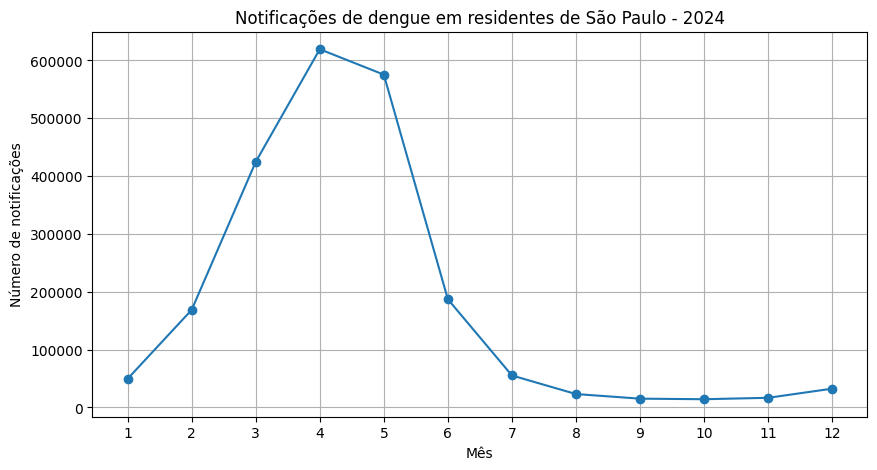

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    tabela_mensal_zip['MES'],
    tabela_mensal_zip['NOTIFICACOES'],
    marker='o'
)

plt.title('Notificações de dengue em residentes de São Paulo - 2024')
plt.xlabel('Mês')
plt.ylabel('Número de notificações')

plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

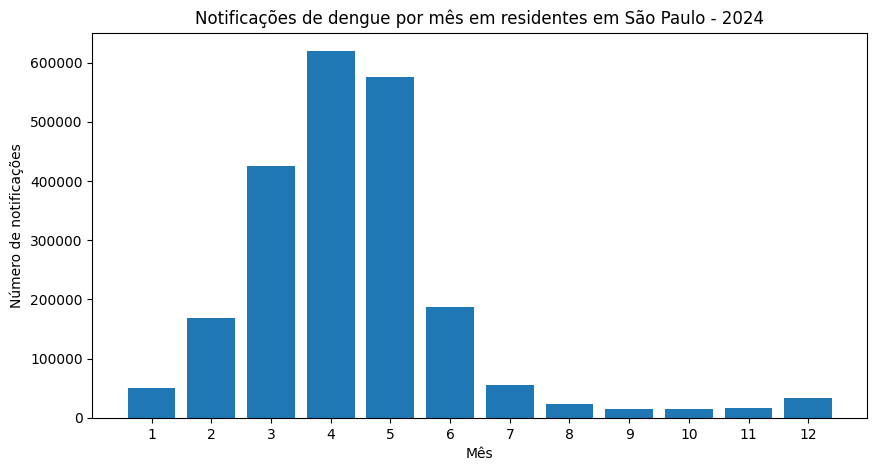

In [55]:
plt.figure(figsize=(10, 5))

plt.bar(
    tabela_mensal_zip['MES'],
    tabela_mensal_zip['NOTIFICACOES']
)

plt.title('Notificações de dengue por mês em residentes em São Paulo - 2024')
plt.xlabel('Mês')
plt.ylabel('Número de notificações')

plt.xticks(range(1, 13))

plt.show()

In [56]:
trimestre1 = tabela_mensal_zip[
    tabela_mensal_zip['MES'] <= 3
]['NOTIFICACOES'].sum()

trimestre2 = tabela_mensal_zip[
    (tabela_mensal_zip['MES'] >= 4) &
    (tabela_mensal_zip['MES'] <= 6)
]['NOTIFICACOES'].sum()

trimestre3 = tabela_mensal_zip[
    (tabela_mensal_zip['MES'] >= 7) &
    (tabela_mensal_zip['MES'] <= 9)
]['NOTIFICACOES'].sum()

trimestre4 = tabela_mensal_zip[
    tabela_mensal_zip['MES'] >= 10
]['NOTIFICACOES'].sum()

print("1º trimestre:", trimestre1)
print("2º trimestre:", trimestre2)
print("3º trimestre:", trimestre3)
print("4º trimestre:", trimestre4)

1º trimestre: 642921
2º trimestre: 1381877
3º trimestre: 93665
4º trimestre: 63389


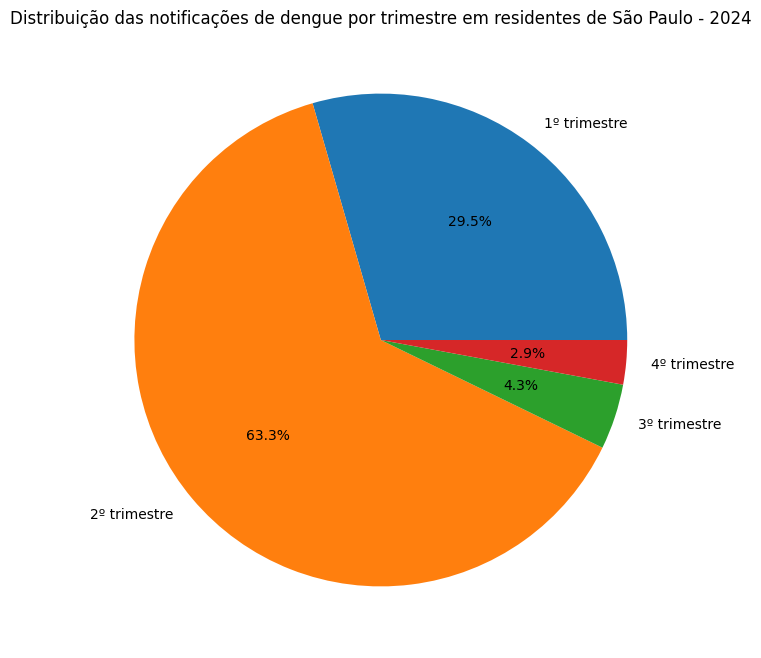

In [57]:
trimestres = [
    '1º trimestre',
    '2º trimestre',
    '3º trimestre',
    '4º trimestre'
]

notificacoes = [
    trimestre1,
    trimestre2,
    trimestre3,
    trimestre4
]

plt.figure(figsize=(8, 8))

plt.pie(
    notificacoes,
    labels=trimestres,
    autopct='%1.1f%%'
)

plt.title('Distribuição das notificações de dengue por trimestre em residentes de São Paulo - 2024')

plt.show()

In [58]:
import numpy as np

notificacoes_array = np.array(tabela_mensal_zip['NOTIFICACOES'])

print("Notificações por mês:")
print(notificacoes_array)

print("Primeiro mês:", notificacoes_array[0])

print("Primeiros três meses:", notificacoes_array[0:3])

print("Total:", np.sum(notificacoes_array))

print("Média mensal:", np.mean(notificacoes_array))

print("Maior valor:", np.max(notificacoes_array))

print("Menor valor:", np.min(notificacoes_array))

Notificações por mês:
[ 49543 168726 424652 619395 575432 187050  55294  23159  15212  14226
  16687  32476]
Primeiro mês: 49543
Primeiros três meses: [ 49543 168726 424652]
Total: 2181852
Média mensal: 181821.0
Maior valor: 619395
Menor valor: 14226


In [59]:
print("Total de notificações:", tabela_mensal_zip['NOTIFICACOES'].sum())

print("Média mensal:", tabela_mensal_zip['NOTIFICACOES'].mean())

print("Maior quantidade mensal:", tabela_mensal_zip['NOTIFICACOES'].max())

print("Menor quantidade mensal:", tabela_mensal_zip['NOTIFICACOES'].min())

Total de notificações: 2181852
Média mensal: 181821.0
Maior quantidade mensal: 619395
Menor quantidade mensal: 14226


In [60]:
total_sp_2024 = 0
datas_invalidas = 0
datas_validas = 0

for pedaco in pd.read_csv(
    '/content/DENGBR24.csv.zip',
    sep=',',
    encoding='latin1',
    usecols=['SG_UF', 'NU_ANO', 'DT_NOTIFIC'],
    chunksize=100000
):
    filtro = pedaco[
        (pedaco['SG_UF'] == 35) &
        (pedaco['NU_ANO'] == 2024)
    ].copy()

    total_sp_2024 = total_sp_2024 + len(filtro)

    filtro['DT_NOTIFIC'] = pd.to_datetime(
        filtro['DT_NOTIFIC'],
        errors='coerce'
    )

    datas_invalidas = datas_invalidas + filtro['DT_NOTIFIC'].isna().sum()

    filtro_limpo = filtro.dropna(subset=['DT_NOTIFIC'])

    datas_validas = datas_validas + len(filtro_limpo)

print("Total de registros:", total_sp_2024)
print("Datas ausentes ou inválidas:", datas_invalidas)
print("Datas válidas:", datas_validas)

Total de registros: 2181852
Datas ausentes ou inválidas: 0
Datas válidas: 2181852


In [61]:
contagem_sexo = {}

for pedaco in pd.read_csv(
    '/content/DENGBR24.csv.zip',
    sep=',',
    encoding='latin1',
    usecols=['SG_UF', 'NU_ANO', 'CS_SEXO'],
    chunksize=100000
):
    filtro = pedaco[
        (pedaco['SG_UF'] == 35) &
        (pedaco['NU_ANO'] == 2024)
    ]

    contagem_pedaco = filtro['CS_SEXO'].fillna('AUSENTE').value_counts()

    for sexo in contagem_pedaco.index:
        quantidade = int(contagem_pedaco[sexo])

        if sexo in contagem_sexo:
            contagem_sexo[sexo] = contagem_sexo[sexo] + quantidade
        else:
            contagem_sexo[sexo] = quantidade

print(contagem_sexo)

{'M': 1002309, 'F': 1177629, 'I': 1909, 'AUSENTE': 5}


### Identificação e tratamento de dados ausentes

Na coluna `CS_SEXO`, foram identificados 5 registros sem preenchimento, entre os 2.181.852 registros de São Paulo em 2024.

Para preservar essas notificações, os valores ausentes foram contabilizados separadamente e apresentados como “Não informado” na tabela-resumo. A categoria `I` foi mantida separada dos valores ausentes.

O arquivo CSV original não foi alterado.

In [62]:
tabela_sexo = pd.DataFrame({
    'SEXO': list(contagem_sexo.keys()),
    'QUANTIDADE': list(contagem_sexo.values())
})

tabela_sexo['SEXO'] = tabela_sexo['SEXO'].replace(
    'AUSENTE',
    'Não informado'
)

print(tabela_sexo)

print("Total:", tabela_sexo['QUANTIDADE'].sum())

            SEXO  QUANTIDADE
0              M     1002309
1              F     1177629
2              I        1909
3  Não informado           5
Total: 2181852


### Resultados e visualizações

Foram elaborados três gráficos para visualizar a distribuição das notificações de dengue registradas para São Paulo em 2024.

O gráfico de linha mostra a evolução mensal das notificações. O maior valor ocorreu em abril, com 619.395 registros, enquanto outubro apresentou o menor valor, com 14.226.

O gráfico de barras facilita a comparação entre os meses, destacando a concentração de notificações entre março e maio.

O gráfico de setores mostra a distribuição por trimestre. O segundo trimestre, de abril a junho, reuniu 1.381.877 notificações, correspondendo a aproximadamente 63,3% do total.

Os resultados descrevem os registros presentes na base de dados. Eles não identificam, por si só, as causas das variações observadas.